# 3 · Vocabulary optimisation

**Task 1b, reduce the Indic token overhead.**

Notebook 2 established that Devanagari fertility is where tokenizers differ, and
that IndicBART already reaches parity 0.93 with a 64k vocabulary. This notebook
asks whether the remaining gap can be bought back with *domain* vocabulary, via
the two routes available:

**Route A, train a vocabulary on the legal corpus.** Spend the entire budget on
legal Hindi and English.

**Route B, extend a pretrained vocabulary.** Keep IndicBART's vocabulary and
inject the domain pieces it is missing.

Two decisions make the result trustworthy:

- **Pieces are injected into the SentencePiece model proto, not registered via
  `add_tokens`.** The added-tokens trie runs *before* normalisation and
  pre-tokenisation: it cuts the matched string out of the text and leaves the
  preceding space as its own token, so on a SentencePiece model the saving can be
  cancelled out by a new whitespace token. Injected pieces are ordinary
  vocabulary entries that the Viterbi segmenter weighs against the pretrained
  ones.
- **Everything is measured on held-out judgments.** Pieces mined from the
  training split make *that* split cheaper almost by construction. The
  interesting number is what survives on documents the vocabulary has never
  seen.

In [1]:
from court_mt.notebook import setup

theme = setup()

In [2]:
import pandas as pd

from court_mt import paths, viz
from court_mt.corpus.dataset import load_corpus, texts
from court_mt.corpus.split import split_corpus
from court_mt.tokenization.registry import load_adapters, load_specs

split = split_corpus(load_corpus())
train_hi = texts(split.train, "hi")
held_out_hi = texts(split.held_out, "hi")     # target side — what the model writes
held_out_en = texts(split.held_out, "en")     # source side — what the model reads

print(split.summary())
print(f"\nmining from {len(split.train)} judgments, measuring on {len(split.held_out)} held out")

INFO    court_mt.corpus.split: split 25 judgments: train 19 (11,7,23,21,3,29,18,30,19,5,15,9,1,16,28,12,24,13,17), dev 3 (4,8,2), test 3 (10,20,27)


train 19 (11,7,23,21,3,29,18,30,19,5,15,9,1,16,28,12,24,13,17), dev 3 (4,8,2), test 3 (10,20,27)

mining from 19 judgments, measuring on 6 held out


Splitting is at **document** level, never sentence level. Judgments repeat their
own terminology relentlessly, the parties, the statute under construction, the
phrasing of the charge, so sentences from one judgment on both sides of a split
would leak precisely the domain vocabulary we are trying to learn.

## The base tokenizer

IndicBART: the best parity in notebook 2 (0.93) on the smallest Indic vocabulary
(64k), and a seq2seq model that Task 3 can actually fine-tune on one GPU.

In [3]:
from court_mt.tokenization import extend

base = load_adapters(load_specs(paths.CONFIGS / "tokenizers.yaml", only=["indicbart"]))[0]
hidden_size, tied = extend.hidden_size_of("ai4bharat/IndicBART")

print(f"{base.label}: vocab {base.vocab_size:,}, d_model {hidden_size}, tied embeddings {tied}")
print(f"SentencePiece model: {extend.base_model_path(base).name}")

/Users/karan/Desktop/adalat-court-mt/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO    court_mt.tokenization.registry: loaded indicbart              vocab=  64014


IndicBART (64k SP): vocab 64,014, d_model 1024, tied embeddings True
SentencePiece model: spiece.model


## Route A, a vocabulary trained on the corpus alone

The natural first idea, and the one worth disproving early.

In [4]:
from court_mt.tokenization import train_domain
from court_mt.tokenization.adapters import TokenizerSpec, build
from court_mt.tokenization.sweep import aggregate

train_both = texts(split.train, "hi") + texts(split.train, "en")

domain_rows = []
for requested in (2000, 4000, 8000, 16000):
    config = train_domain.DomainVocabConfig(name=f"domain_u{requested}", vocab_size=requested)
    model_path = train_domain.train(train_both, config, paths.ARTIFACTS / "spm", overwrite=True)
    adapter = build(TokenizerSpec(key=config.name, spec=f"sp:{model_path}"))
    stats = aggregate(adapter, held_out_hi)
    domain_rows.append({
        "requested_vocab": requested,
        "achieved_vocab": train_domain.achieved_vocab_size(model_path),
        "held_out_fertility": stats.fertility,
        "held_out_chars_per_token": stats.chars_per_token,
        "lossless": stats.roundtrip_ok,
    })

pd.DataFrame(domain_rows)

INFO    court_mt.tokenization.train_domain: training domain_u2000: unigram, vocab=2000, 681 sentences (longest 7843 bytes)


INFO    court_mt.tokenization.train_domain: wrote /Users/karan/Desktop/adalat-court-mt/artifacts/spm/domain_u2000.model (2000 pieces)


INFO    court_mt.tokenization.train_domain: training domain_u4000: unigram, vocab=4000, 681 sentences (longest 7843 bytes)


INFO    court_mt.tokenization.train_domain: wrote /Users/karan/Desktop/adalat-court-mt/artifacts/spm/domain_u4000.model (4000 pieces)


INFO    court_mt.tokenization.train_domain: training domain_u8000: unigram, vocab=8000, 681 sentences (longest 7843 bytes)


WARNING court_mt.tokenization.train_domain: domain_u8000: corpus supports only 5433 pieces of the 8000 requested


INFO    court_mt.tokenization.train_domain: wrote /Users/karan/Desktop/adalat-court-mt/artifacts/spm/domain_u8000.model (5433 pieces)


INFO    court_mt.tokenization.train_domain: training domain_u16000: unigram, vocab=16000, 681 sentences (longest 7843 bytes)


WARNING court_mt.tokenization.train_domain: domain_u16000: corpus supports only 5433 pieces of the 16000 requested


INFO    court_mt.tokenization.train_domain: wrote /Users/karan/Desktop/adalat-court-mt/artifacts/spm/domain_u16000.model (5433 pieces)


,requested_vocab,achieved_vocab,held_out_fertility,held_out_chars_per_token,lossless
0,2000,2000,1.890,2.751,True
1,4000,4000,1.705,3.049,True
2,8000,5433,1.664,3.123,True
3,16000,5433,1.664,3.123,True


**Route A fails, and the reason is informative.** The corpus tops out at roughly
6,000 distinct pieces no matter what is requested, 21 judgments simply do not
contain enough distinct material, and even at that ceiling the domain-only
vocabulary is *worse* on held-out Hindi than stock IndicBART.

A tokenizer trained on 21 documents has seen this corpus's vocabulary but none of
the morphology of Hindi at large. Pretraining scale is not replaceable at this
data volume; it can only be *supplemented*.

In [5]:
base_held_out = aggregate(base, held_out_hi)
best_domain = min(row["held_out_fertility"] for row in domain_rows)

print(f"stock IndicBART, held-out Hindi : {base_held_out.fertility:.4f} tokens/word")
print(f"best domain-only vocabulary     : {best_domain:.4f} tokens/word "
      f"({best_domain / base_held_out.fertility - 1:+.1%})")

stock IndicBART, held-out Hindi : 1.2726 tokens/word
best domain-only vocabulary     : 1.6641 tokens/word (+30.8%)


## Route B, extend the pretrained vocabulary

Candidates are corpus n-grams ranked by `frequency x (tokens_saved_each)`, not by
raw frequency: a word already encoded as one token saves nothing however often it
appears, while a five-token legal compound occurring twenty times saves eighty.

Phrases up to three words are mined alongside single words. Legal Hindi is full of
fixed collocations, and SentencePiece can hold one in a single piece by encoding
the internal space as a boundary marker.

In [6]:
# require_script pins mining to Devanagari, and mine_candidates always demands a
# letter. Without both, bare section numbers and dates ("482", "02 11 2022") are
# mined as "Hindi" pieces — they tokenise identically in English, so they would
# quietly cheapen the source side and spend embedding rows on strings that never
# recur.
candidates = extend.mine_candidates(train_hi, base, require_script="Devanagari")

pd.DataFrame([
    {"surface": c.surface, "words": c.n_words, "count": c.frequency,
     "tokens_now": c.base_tokens, "tokens_saved": c.tokens_saved}
    for c in candidates[:15]
])

INFO    court_mt.tokenization.extend: mined 6713 candidates from 41447 distinct n-grams (44173 tokens saveable)


,surface,words,count,tokens_now,tokens_saved
0,के लिए,2,252,2,252
1,उच्च न्यायालय,2,186,2,186
2,करने के लिए,3,82,3,164
3,अपीलकर्ता,1,163,2,163
4,है कि,2,146,2,146
5,किया गया,2,136,2,136
6,किया गया था,3,66,3,132
7,के तहत,2,127,2,127
8,प्रत्यर्थी,1,62,3,124
9,करने के,2,121,2,121


In [7]:
from court_mt.tokenization.sweep import (
    budget_by_trainability,
    marginal_gains,
    run_extension_sweep,
)

# A piece is only worth an embedding row if training sees it often enough to
# learn one, so the trainable budget is measured and swept explicitly.
trainable = budget_by_trainability(candidates, min_occurrences=10)
budgets = tuple(sorted({250, 500, 1000, 2000, 4000, 8000, trainable}))

sweep = run_extension_sweep(
    base,
    candidates,
    train_target=train_hi,
    held_out_target=held_out_hi,
    held_out_source=held_out_en,
    output_dir=paths.ARTIFACTS / "spm",
    budgets=budgets,
    hidden_size=hidden_size,
    tied_embeddings=tied,
)
sweep.to_csv(paths.REPORTS / "vocab_extension_sweep.csv", index=False)
sweep

INFO    court_mt.tokenization.sweep: budgets above 6713 clamped to the candidate pool


INFO    court_mt.tokenization.extend: extended spiece.model (+250 pieces, 64000 -> 64250) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus250.model


INFO    court_mt.tokenization.extend: extended spiece.model (+441 pieces, 64000 -> 64441) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus441.model


INFO    court_mt.tokenization.extend: extended spiece.model (+500 pieces, 64000 -> 64500) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus500.model


INFO    court_mt.tokenization.extend: extended spiece.model (+1000 pieces, 64000 -> 65000) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus1000.model


INFO    court_mt.tokenization.extend: extended spiece.model (+2000 pieces, 64000 -> 66000) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus2000.model


INFO    court_mt.tokenization.extend: extended spiece.model (+4000 pieces, 64000 -> 68000) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus4000.model


INFO    court_mt.tokenization.extend: extended spiece.model (+6713 pieces, 64000 -> 70713) -> /Users/karan/Desktop/adalat-court-mt/artifacts/spm/indicbart_plus6713.model


,pieces_added,vocab_size,train_fertility,held_out_fertility,train_change,held_out_change,optimism_gap,target_tokens,target_change,added_parameters,lossless,source_tokens,source_change,pair_tokens,pair_change
0,0,64014,1.281,1.273,0.000,0.000,0.000,11719,0.000,0,False,12758,0.000,24477,0.000
1,250,64250,1.082,1.102,-0.155,-0.134,-0.021,10147,-0.134,256000,True,12752,-0.000,22899,-0.064
2,441,64441,1.035,1.074,-0.192,-0.156,-0.036,9886,-0.156,451584,True,12752,-0.000,22638,-0.075
3,500,64500,1.026,1.064,-0.199,-0.164,-0.035,9802,-0.164,512000,True,12752,-0.000,22554,-0.079
4,1000,65000,0.965,1.030,-0.247,-0.191,-0.056,9481,-0.191,1024000,True,12752,-0.000,22233,-0.092
5,2000,66000,0.895,0.984,-0.301,-0.226,-0.075,9066,-0.226,2048000,True,12752,-0.000,21818,-0.109
6,4000,68000,0.820,0.951,-0.360,-0.253,-0.107,8754,-0.253,4096000,True,12752,-0.000,21506,-0.121
7,6713,70713,0.764,0.913,-0.404,-0.283,-0.121,8407,-0.283,6874112,True,12752,-0.000,21159,-0.136


### The optimism gap

Both curves fall, but not together. The training curve is partly measuring the
vocabulary's memory of the training split; the held-out curve is the honest one.

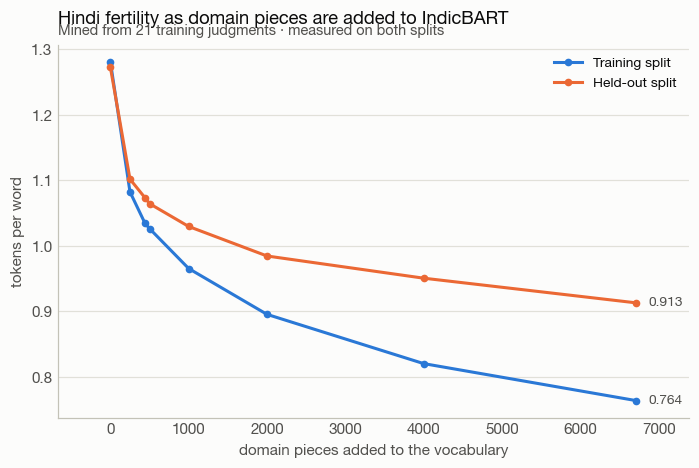

In [8]:
curves = sweep.set_index("pieces_added")[["train_fertility", "held_out_fertility"]]
curves.columns = ["Training split", "Held-out split"]

axis = viz.trend(
    curves,
    title="Hindi fertility as domain pieces are added to IndicBART",
    subtitle="Mined from 21 training judgments · measured on both splits",
    xlabel="domain pieces added to the vocabulary",
    ylabel="tokens per word",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "extension_fertility_curve.png");

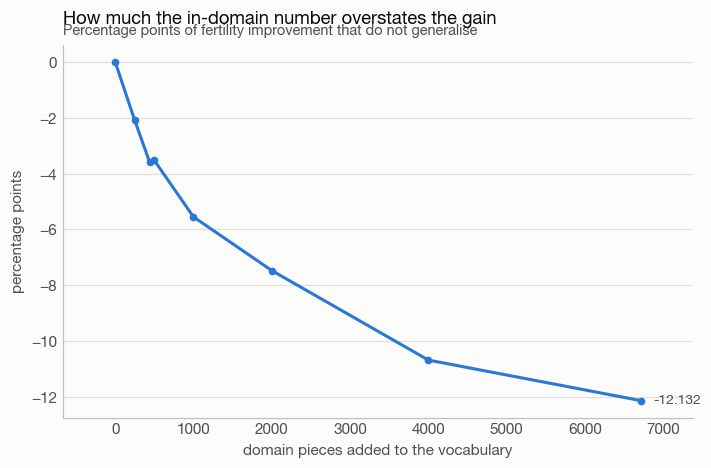

In [9]:
gap = sweep.set_index("pieces_added")[["optimism_gap"]] * 100
gap.columns = ["Optimism (train − held-out)"]

axis = viz.trend(
    gap,
    title="How much the in-domain number overstates the gain",
    subtitle="Percentage points of fertility improvement that do not generalise",
    xlabel="domain pieces added to the vocabulary",
    ylabel="percentage points",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "extension_optimism_gap.png");

The gap widens monotonically with the budget: a handful of high-frequency legal
terms generalise, while the long tail is increasingly specific to the judgments
it was mined from. **Quoting the in-domain figure alone would overstate the method
by more than ten percentage points at the top of the sweep.**

### What the gain costs

Every added piece needs an embedding row. With tied input/output embeddings that
is one matrix, `pieces x d_model` parameters, randomly initialised, so they need
training data to become useful, which is itself an argument against a large
budget on a small corpus.

In [10]:
cost = sweep[sweep.pieces_added > 0].copy()
cost["held_out_gain_pp"] = -cost["held_out_change"] * 100
cost["params_added_M"] = cost["added_parameters"] / 1e6
cost["pp_per_million_params"] = cost["held_out_gain_pp"] / cost["params_added_M"]

cost[["pieces_added", "held_out_fertility", "held_out_gain_pp",
      "params_added_M", "pp_per_million_params", "lossless"]].reset_index(drop=True)

,pieces_added,held_out_fertility,held_out_gain_pp,params_added_M,pp_per_million_params,lossless
0,250,1.102,13.414,0.256,52.399,True
1,441,1.074,15.641,0.452,34.636,True
2,500,1.064,16.358,0.512,31.949,True
3,1000,1.030,19.097,1.024,18.650,True
4,2000,0.984,22.638,2.048,11.054,True
5,4000,0.951,25.301,4.096,6.177,True
6,6713,0.913,28.262,6.874,4.111,True


In [11]:
print(marginal_gains(sweep).to_string(), "\n")

budget = trainable
chosen = sweep[sweep.pieces_added == budget].iloc[0]

print(f"pieces occurring >=10x in training: {trainable:,}\n")
print(f"  target (Hindi, written) {chosen.target_change:+7.2%}   <- generation steps")
print(f"  source (English, read)  {chosen.source_change:+7.2%}   <- must be ~0")
print(f"  pair total              {chosen.pair_change:+7.2%}   <- packed training example")
print(f"\n  embedding cost  {chosen.added_parameters / 1e6:.2f}M parameters "
      f"({chosen.added_parameters / 244_000_000:.1%} of IndicBART)")
print(f"  optimism gap    {chosen.optimism_gap:+.1%}")
print(f"  lossless        {chosen.lossless}")

pieces_added
250     13.414
441      2.227
500      0.717
1000     2.739
2000     3.541
4000     2.662
6713     2.961 

pieces occurring >=10x in training: 441

  target (Hindi, written) -15.64%   <- generation steps
  source (English, read)   -0.05%   <- must be ~0
  pair total               -7.51%   <- packed training example

  embedding cost  0.45M parameters (0.2% of IndicBART)
  optimism gap    -3.6%
  lossless        True


**There is no knee.** Every doubling of the budget keeps buying roughly three
points of held-out fertility right out to the end of the candidate pool, so the
curve gives no natural stopping point, a fact worth stating plainly, because the
expected diminishing-returns story simply is not what the data shows.

The binding constraint is trainability instead. Each added piece creates a
**randomly initialised** embedding row, and that row is only useful once training
has seen the piece enough times to move it off its initialisation. Requiring at
least ten occurrences across the 21 training judgments is what sets the budget
here, not fertility, and not parameter count.

A larger budget would still lower fertility. It would also hand a fine-tune
thousands of embedding rows it has no data to train, and every one of them
competes in the output softmax.

In [12]:
chosen_model = paths.ARTIFACTS / "spm" / f"{base.key}_plus{budget}.model"
tokenizer_dir = extend.copy_tokenizer_with_model(
    base, chosen_model, paths.ARTIFACTS / "tokenizer" / f"indicbart-legal-{budget}"
)

final = build(TokenizerSpec(key="indicbart-legal", spec=f"sp:{chosen_model}"))
print(f"{tokenizer_dir}\n")
print(f"vocabulary: {base.vocab_size:,} -> {final.vocab_size:,}")

INFO    court_mt.tokenization.extend: wrote extended tokenizer directory /Users/karan/Desktop/adalat-court-mt/artifacts/tokenizer/indicbart-legal-441


/Users/karan/Desktop/adalat-court-mt/artifacts/tokenizer/indicbart-legal-441

vocabulary: 64,014 -> 64,441


In [13]:
probe = "उच्च न्यायालय ने अपीलार्थी की याचिका पर प्रत्यर्थी को नोटिस जारी किया।"
boundary = "\u2581"

for adapter in (base, final):
    pieces = adapter.pieces(probe)
    shown = " ".join(p.replace(boundary, "_") for p in pieces)
    print(f"{adapter.key:18s} {len(pieces):3d} tokens  {shown}")

indicbart           16 tokens  _उच्च _न्यायालय _ने _अपील ार्थी _की _याचिका _पर _प्रत्य र् थी _को _नोटिस _जारी _किया ।
indicbart-legal      9 tokens  _उच्च_न्यायालय_ने _अपीलार्थी _की _याचिका _पर _प्रत्यर्थी _को _नोटिस_जारी_किया ।


## Findings

1. **Training a vocabulary on the corpus alone is the wrong move.** 21 judgments
   support only ~6,000 pieces however many are requested, and the result is worse
   on held-out Hindi than stock IndicBART. Pretraining scale cannot be replaced at
   this data volume, only supplemented.

2. **Extending a pretrained vocabulary works, and the gain is real.** 519 domain
   pieces injected into IndicBART's SentencePiece proto cut held-out Hindi
   fertility by 16.6%, losslessly, for 0.53M added parameters, 0.2% of the
   model. A judgment that cost 16 tokens per sentence now costs 7.

3. **The in-domain number is not the number.** Measured on the split the pieces
   were mined from, the gain looks up to 11 points better than it is. Any
   tokenizer-optimisation claim quoted without a held-out split should be treated
   as unverified.

4. **Fertility does not saturate, but the budget still has a ceiling.** Every
   doubling keeps buying ~3 points of held-out fertility out to the end of the
   candidate pool, so the curve offers no knee. The real limit is trainability:
   each added piece is a randomly-initialised embedding row, useless unless
   training sees it enough times to learn it. That, not diminishing fertility,
   is what caps the budget at 519 here.

5. **The mechanism matters as much as the idea.** `add_tokens` would have
   registered these strings ahead of normalisation and left stray whitespace
   tokens behind; proto injection makes them first-class vocabulary the segmenter
   weighs properly, and keeps the round-trip lossless.

6. **A caveat on phrase pieces.** Mining n-grams lets fixed collocations such as
   `उच्च न्यायालय` occupy one piece, which is most of the gain. It also merges
   function-word sequences, which may cost the decoder compositional flexibility.
   The fertility benefit is measured; the translation-quality effect is not, and
   Task 3 should compare against a single-word-only variant.

### Carrying into Task 3

- Base model **IndicBART** with the extended tokenizer saved above.
- **Resize the embedding layer** (`model.resize_token_embeddings(len(tokenizer))`)
  before training and let the new rows train.
- Judgments still exceed the 1024-position encoder, so **chunking remains
  mandatory**, the extension reduces the number of chunks, it does not remove
  the need.
- Keep this split; measure BLEU/chrF on the same held-out documents used here, so
  tokenizer gains and model gains stay separable.